In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from helpers import make_preprocessor, evaluate


In [3]:
df = pd.read_csv('data/ames_housing.csv')
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_df = train_df.drop(index=[523, 1298])
X_train = train_df.drop(columns=['SalePrice', 'Id', 'GarageYrBlt', 'PoolArea'])
y_train = train_df['SalePrice']

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")

Shape of X_train: (1166, 77)
Shape of y_train: (1166,)


In [5]:
from sklearn.linear_model import LinearRegression
mae, spread, rmse, r2 = evaluate(LinearRegression(), X_train, y_train)
print(mae, spread, rmse, r2)

17207.463617697722 612.8742141611775 25395.88625441448 0.8896753334786069


In [6]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest":     RandomForestRegressor(n_estimators=500, max_depth=20, max_features=0.3, min_samples_leaf=1, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42),
    "XGBoost":           XGBRegressor(n_estimators=1000, learning_rate=0.1, max_depth=2, random_state=42, n_jobs=-1),
    "LightGBM":          LGBMRegressor(n_estimators=600, learning_rate=0.1, num_leaves=4, random_state=42, n_jobs=-1, verbose=-1),
    "CatBoost":          CatBoostRegressor(random_state=42, verbose=0, allow_writing_files=False),
}

rows = []
for name, model in models.items():
    mae, spread, rmse, r2 = evaluate(model, X_train, y_train)
    rows.append({"Model": name, "MAE": mae, "Spread": spread, "RMSE": rmse, "R2": r2})

results = pd.DataFrame(rows).sort_values("MAE")
results.round({"MAE": 0, "Spread": 0, "RMSE": 0, "R2": 3})


,Model,MAE,Spread,RMSE,R2
5,CatBoost,14438.0,854.0,23436.0,0.908
4,LightGBM,14699.0,893.0,23377.0,0.908
3,XGBoost,14781.0,328.0,23093.0,0.910
2,Gradient Boosting,15227.0,780.0,23783.0,0.904
1,Random Forest,16583.0,1416.0,26331.0,0.883
0,Linear Regression,17207.0,613.0,25396.0,0.890


## All tuned models

Same cleaned training data, same preprocessing and same 5-fold split for every model. Each model uses the settings chosen in the tuning notebooks.

| Model | MAE | Spread (MAE) | RMSE | R² |
|---|---|---|---|---|
| CatBoost | $14,438 | 854 | $23,436 | 0.908 |
| LightGBM | $14,699 | 893 | $23,377 | 0.908 |
| XGBoost | $14,781 | 328 | $23,093 | 0.910 |
| Gradient Boosting | $15,227 | 780 | $23,783 | 0.904 |
| Random Forest | $16,583 | 1,416 | $26,331 | 0.883 |
| Linear Regression | $17,207 | 613 | $25,396 | 0.890 |

1. **CatBoost, LightGBM and XGBoost are effectively tied.** Their MAEs are within $343 of each other, less than their fold-to-fold spreads.
2. **XGBoost has the best RMSE and R² and the steadiest folds**, so it makes fewer large errors. CatBoost has the best MAE, so it is slightly better on typical houses.
3. **Random Forest beats the baseline on MAE but not on RMSE**, which means it makes some large errors.
4. **Caveat:** each tuned setting was chosen on the same folds it is scored on, so these numbers are slightly optimistic. The test set has not been used yet.

The final model will be chosen after trying stacking.

In [15]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV

stack = StackingRegressor(
    estimators=[('cat', models['CatBoost']),
                  ('lgb', models['LightGBM']),
                  ('xgb', models['XGBoost'])],
                final_estimator = RidgeCV(),
    cv=5 
)

mae, spread, rmse, r2 = evaluate(stack, X_train, y_train)
print(mae, spread, rmse, r2)

14345.3176855651 506.05281866593236 22627.596133277686 0.9134061730236009


## Stacking and the final model

A stack of the three best boosting models (CatBoost, LightGBM, XGBoost) with a Ridge regression on top, scored with the same 5-fold split.

| Model | MAE | Spread (MAE) | RMSE | R² |
|---|---|---|---|---|
| Stack (CatBoost + LightGBM + XGBoost, Ridge on top) | $14,345 | 506 | $22,628 | 0.913 |
| CatBoost | $14,438 | 854 | $23,436 | 0.908 |
| XGBoost | $14,781 | 328 | $23,093 | 0.910 |

The stack beats CatBoost by $93 on MAE, about a fifth of the stack's own fold-to-fold spread, so the two are effectively tied. The gain on RMSE (about 2% against XGBoost) is small, and the base models are all tree boosters, so their mistakes are similar.

**Final model: CatBoost with default settings.** It has the best MAE of the single models, needs no tuning (the grid search did not beat the defaults), and is much simpler and cheaper to train and run than a stack of three boosters plus a Ridge. XGBoost has a slightly better RMSE and steadier folds, a gap of about 1.5%. CatBoost's cost is that its default trees are deeper than the tuned XGBoost and LightGBM models, so it may be slower to train than those two.

These scores come from cross-validation on the training set, and the settings were chosen on the same folds, so they are slightly optimistic. The test set has not been used. It is scored once, with this final model, in the next step.

In [17]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from catboost import CatBoostRegressor

X_test = test_df.drop(columns=['SalePrice', 'Id', 'GarageYrBlt', 'PoolArea'])
y_test = test_df['SalePrice']
print(X_test.shape)

final_model = Pipeline([('prep', make_preprocessor(X_train)),
                        ('model', CatBoostRegressor(random_state=42, verbose=0, allow_writing_files=False))])
final_model.fit(X_train, y_train)
pred = final_model.predict(X_test)

print("MAE: ", mean_absolute_error(y_test, pred))
print("RMSE:", root_mean_squared_error(y_test, pred))
print("R2:  ", r2_score(y_test, pred))

(292, 77)
MAE:  15021.772110516129
RMSE: 24407.48667460289
R2:   0.9223337587373115


In [18]:
baseline = Pipeline([('prep', make_preprocessor(X_train)), ('model', LinearRegression())])
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)

print("Baseline MAE: ", mean_absolute_error(y_test, base_pred))
print("Baseline RMSE:", root_mean_squared_error(y_test, base_pred))
print("Baseline R2:  ", r2_score(y_test, base_pred))

Baseline MAE:  17826.37868685433
Baseline RMSE: 27945.852925258132
Baseline R2:   0.8981828575962798


## Final evaluation on the test set

The test set (292 houses) was scored once, after all choices were made. Both models were fitted on the cleaned training set (1,166 houses) with the same preprocessing. The test houses were not cleaned: the two unfinished sales removed from training were in the training part only.

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression (baseline) | $17,826 | $27,946 | 0.898 |
| CatBoost (final) | $15,022 | $24,407 | 0.922 |

1. **The final model is about 16% better than the baseline on MAE** and about 13% better on RMSE. The cross-validation gap was about 13% on MAE, so the two agree.
2. **Test MAE is about $580 higher than the cross-validation MAE ($14,438)**, which is within the fold-to-fold spread ($854). The settings were chosen on the cross-validation folds, so those scores were slightly optimistic.
3. **In plain terms:** on houses the model has never seen, its price is off by about $15,000 on average (about 8% of the $180,000 average price).
4. **Limits:** 292 houses is a small sample, no confidence interval has been computed, and the model describes associations in Ames, Iowa sales, not causes.

In [19]:
from sklearn.inspection import permutation_importance

result = permutation_importance(final_model, X_test, y_test, 
                                n_repeats=10, random_state=42,
                                scoring='neg_mean_absolute_error', n_jobs=1)


importance = pd.Series(result.importances_mean, index=X_test.columns)
importance.sort_values(ascending=False).head(10).round(0)

OverallQual    11163.0
GrLivArea       8154.0
BsmtFinSF1      1985.0
1stFlrSF        1813.0
TotalBsmtSF     1453.0
LotArea         1371.0
OverallCond     1323.0
YearBuilt       1191.0
GarageCars      1100.0
BsmtQual         847.0
dtype: float64

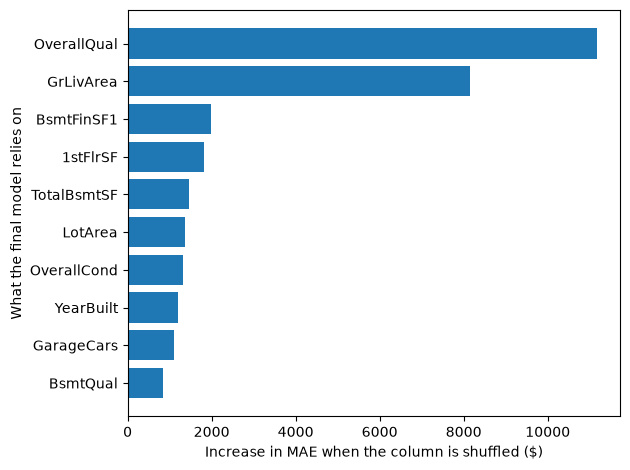

In [22]:
import matplotlib.pyplot as plt

top = importance.sort_values().tail(10)
plt.barh(top.index, top.values)
plt.xlabel('Increase in MAE when the column is shuffled ($)')
plt.ylabel('What the final model relies on')
plt.tight_layout()
plt.savefig('reports_importance.png', dpi=150)
plt.show()

## What the final model relies on

Permutation importance on the test set: each column was shuffled 10 times among the 292 test houses, and the table shows how much the MAE rises in dollars. A larger number means the model depends on that column more.

![Permutation importance of the final CatBoost model](reports_importance.png)

| Column | Increase in MAE |
|---|---|
| `OverallQual` | $11,163 |
| `GrLivArea` | $8,154 |
| `BsmtFinSF1` | $1,985 |
| `1stFlrSF` | $1,813 |
| `TotalBsmtSF` | $1,453 |

1. **Two columns carry most of the model:** the overall quality rating and the living area. The third column is about a sixth as important as the first.
2. **In plain terms:** the model prices a house mostly by how well it is built and finished, and how big it is. This matches the correlations found during EDA.
3. **Basement and floor-area columns overlap** (`BsmtFinSF1`, `1stFlrSF`, `TotalBsmtSF`), so each one looks modest even though the group matters.
4. **Limits:** this shows what the model uses, not what causes a price. The importances were measured on 292 houses, so the small values (under about $1,000) are noisy.